> **Course source:** [langgraph/mail_sorting.ipynb](https://huggingface.co/agents-course/notebooks/blob/cecf8edffb02101c90634b84076bd93b1a20c713/unit2/langgraph/mail_sorting.ipynb).
> **Compatibility:** Uses exact SPAM/HAM labels and verifies both routing branches on the course's example emails. Local callback events reuse the original runs. Langfuse Cloud export needs separate keys and an explicit opt-in.

# Alfred the Mail Sorting Butler: A LangGraph Example

In this notebook, **we're going to build a complete email processing workflow using LangGraph**.

This notebook is part of the <a href="https://www.hf.co/learn/agents-course">Hugging Face Agents Course</a>, a free course from beginner to expert, where you learn to build Agents.

![Agents course share](https://huggingface.co/datasets/agents-course/course-images/resolve/main/en/communication/share.png)

## What You'll Learn

In this notebook, you'll learn how to:
1. Set up a LangGraph workflow
2. Define state and nodes for email processing
3. Create conditional branching in a graph
4. Connect an LLM for classification and content generation
5. Visualize the workflow graph
6. Execute the workflow with example data

In [1]:
COURSE_PACKAGES = ['langgraph==1.2.22', 'langchain-openai==1.8.0']

import os
import subprocess
import sys

if not os.environ.get("HF_COURSE_BATCH"):
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                    "--disable-pip-version-check", *COURSE_PACKAGES], check=True, timeout=600)

## Setting Up Our Environment

First, let's import all the necessary libraries. LangGraph provides the graph structure, while LangChain offers convenient interfaces for working with LLMs.

In [2]:
import json
import os
from functools import lru_cache

import httpx
from openai import OpenAI

GROQ_BASE = "https://api.groq.com/openai/v1"
QWEN = "qwen/qwen3.8-27b"
GPT_OSS = ("openai/gpt-oss-20b", "openai/gpt-oss-120b")


def optional_secret(name):
    """Read a notebook-authorized secret without printing it."""
    if os.getenv(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except ImportError:
        return None
    except Exception as exc:
        if type(exc).__name__ in {"SecretNotFoundError", "NotebookAccessError"}:
            return None
        raise


@lru_cache(maxsize=1)
def groq_account():
    key = optional_secret("GROQ_API_KEY")
    if not key:
        raise RuntimeError("Enable notebook access to the GROQ_API_KEY secret in Colab.")
    with OpenAI(api_key=key, base_url=GROQ_BASE, timeout=20, max_retries=0) as client:
        return key, frozenset(model.id for model in client.models.list().data)


class ModelRouting:
    def __init__(self, models, mode):
        self.models = list(models)
        self.mode = mode

    def requests(self, request):
        if request.method != "POST" or not request.url.path.endswith("/chat/completions"):
            yield None, request
            return
        body = json.loads(request.content)
        headers = {key: val for key, val in request.headers.items()
                   if key not in {"content-length", "transfer-encoding"}}
        if self.mode == "code" and body.get("tools"):
            raise ValueError("CodeAgent uses Python actions. Its API request must have no native tools.")
        for model_id in tuple(self.models):
            payload = {**body, "model": model_id}
            max_tokens = payload.pop("max_tokens", None)
            if max_tokens and "max_completion_tokens" not in payload:
                payload["max_completion_tokens"] = max_tokens
            if model_id in GPT_OSS:
                payload.pop("parallel_tool_calls", None)
                payload.pop("stop", None)
                payload["reasoning_effort"] = "low"
            elif model_id == QWEN:
                payload["reasoning_effort"] = "none"
            yield model_id, httpx.Request(
                request.method, request.url, json=payload, headers=headers,
                extensions=request.extensions,
            )

    def accept(self, model_id, status, attempt):
        if model_id is None:
            return True
        if status in {429, 503} and attempt < len(self.models):
            return False
        if 200 <= status < 300 and model_id != self.models[0]:
            self.models.remove(model_id)
            self.models.insert(0, model_id)
            print(f"Groq fallback model: {model_id}", flush=True)
        return True


class CourseTransport(httpx.HTTPTransport):
    def __init__(self, routing):
        super().__init__(retries=0)
        self.routing = routing

    def handle_request(self, request):
        for attempt, (model_id, candidate) in enumerate(self.routing.requests(request), 1):
            response = super().handle_request(candidate)
            if self.routing.accept(model_id, response.status_code, attempt):
                return response
            response.close()


class AsyncCourseTransport(httpx.AsyncHTTPTransport):
    def __init__(self, routing):
        super().__init__(retries=0)
        self.routing = routing

    async def handle_async_request(self, request):
        for attempt, (model_id, candidate) in enumerate(self.routing.requests(request), 1):
            response = await super().handle_async_request(candidate)
            if self.routing.accept(model_id, response.status_code, attempt):
                return response
            await response.aclose()


@lru_cache(maxsize=3)
def groq_route(mode):
    key, available = groq_account()
    candidates = {
        "text": (QWEN, *GPT_OSS),
        "vision": (QWEN,),
        "code": (QWEN, *GPT_OSS),
    }[mode]
    models = [model_id for model_id in candidates if model_id in available]
    if not models:
        raise RuntimeError(f"None of the Groq {mode} models are enabled for this project: {candidates}")
    print(f"Groq {mode} candidates, in order: {', '.join(models)}", flush=True)
    return key, ModelRouting(models, mode)


@lru_cache(maxsize=1)
def make_groq_llm():
    from llama_index.llms.openai_like import OpenAILike
    key, routing = groq_route("text")
    return OpenAILike(
        model=routing.models[0], api_base=GROQ_BASE, api_key=key,
        is_chat_model=True, is_function_calling_model=True, context_window=32768,
        max_tokens=1024, temperature=0.1, timeout=30, max_retries=0,
        http_client=httpx.Client(transport=CourseTransport(routing), timeout=30),
        async_http_client=httpx.AsyncClient(transport=AsyncCourseTransport(routing), timeout=30),
    )


@lru_cache(maxsize=2)
def make_chat_model(mode="text"):
    from langchain_openai import ChatOpenAI
    key, routing = groq_route(mode)
    return ChatOpenAI(
        model=routing.models[0], base_url=GROQ_BASE, api_key=key,
        temperature=0.1, max_tokens=1024, timeout=30, max_retries=0,
        http_client=httpx.Client(transport=CourseTransport(routing), timeout=30),
        http_async_client=httpx.AsyncClient(transport=AsyncCourseTransport(routing), timeout=30),
    )


@lru_cache(maxsize=1)
def make_code_model():
    from smolagents import OpenAIModel
    key, routing = groq_route("code")
    return OpenAIModel(
        model_id=routing.models[0], api_base=GROQ_BASE, api_key=key,
        max_tokens=1800, temperature=0.1, retry=False,
        client_kwargs={
            "http_client": httpx.Client(transport=CourseTransport(routing), timeout=30),
            "timeout": 30, "max_retries": 0,
        },
    )

def display_course_graph(graph):
    import json
    import shutil
    from IPython.display import Image, display
    mermaid = graph.draw_mermaid()
    print(mermaid)
    if not shutil.which("dot"):
        print("Graphviz is unavailable. The compiled graph is listed above in Mermaid.")
        return
    dot = ["digraph course {", "rankdir=TB;", 'node [shape=box, style=rounded];']
    for node_id in graph.nodes:
        dot.append(f"{json.dumps(node_id)};")
    for edge in graph.edges:
        label = json.dumps(str(edge.data or ""))
        style = "dashed" if edge.conditional else "solid"
        dot.append(f"{json.dumps(edge.source)} -> {json.dumps(edge.target)} [label={label},style={style}];")
    dot.append("}")
    png = subprocess.run(["dot", "-Tpng"], input="\n".join(dot).encode(),
                         capture_output=True, check=True, timeout=10).stdout
    display(Image(png))


In [3]:
from langchain_core.callbacks import BaseCallbackHandler
from typing import TypedDict, List, Dict, Any, Optional
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage



## Step 1: Define Our State

In LangGraph, **State** is the central concept. It represents all the information that flows through our workflow.

For Alfred's email processing system, we need to track:
- The email being processed
- Whether it's spam or not
- The draft response (for legitimate emails)
- Conversation history with the LLM

In [4]:
class EmailState(TypedDict):
    email: Dict[str, Any]
    is_spam: Optional[bool]
    spam_reason: Optional[str]
    email_category: Optional[str]
    email_draft: Optional[str]
    messages: List[Dict[str, Any]]

## Step 2: Define Our Nodes

In [5]:
def read_email(state: EmailState):
    email = state["email"]
    print(f"Alfred is processing an email from {email['sender']} with subject: {email['subject']}")
    return {}


def classify_email(state: EmailState):
    email = state["email"]

    prompt = f"""
As Alfred the butler of Mr wayne and it's SECRET identity Batman, analyze this email and determine if it is spam or legitimate and should be brought to Mr wayne's attention.

Email:
From: {email['sender']}
Subject: {email['subject']}
Body: {email['body']}

An unsolicited sales pitch, mass promotion or scam belongs in SPAM.
A message with a concrete threat or safety concern for Mr. Wayne belongs in HAM, even from a hostile sender, because he must see it.
Classify the email as SPAM or HAM under this policy.
answer with SPAM or HAM if it's legitimate. Only return the answer
Answer :
    """
    messages = [HumanMessage(content=prompt)]
    response = make_chat_model().invoke(messages)

    import re
    label = re.fullmatch(r"(?:ANSWER\s*:\s*)?(SPAM|HAM)[.!]?", response.content.strip(), re.IGNORECASE)
    if not label:
        raise ValueError(f"Expected SPAM or HAM, received {response.content!r}")
    response_text = label.group(1).upper()
    print(response_text)
    is_spam = response_text == "SPAM"

    if not is_spam:
        new_messages = state.get("messages", []) + [
            {"role": "user", "content": prompt},
            {"role": "assistant", "content": response.content}
        ]
    else:
        new_messages = state.get("messages", [])

    return {
        "is_spam": is_spam,
        "messages": new_messages
    }


def handle_spam(state: EmailState):
    print(f"Alfred has marked the email as spam.")
    print("Course simulation: the email would move to the spam folder.")
    return {}


def drafting_response(state: EmailState):
    email = state["email"]

    prompt = f"""
As Alfred the butler, draft a polite preliminary response to this email.

Email:
From: {email['sender']}
Subject: {email['subject']}
Body: {email['body']}

Draft a brief, professional response that Mr. Wayne can review and personalize before sending.
    """

    messages = [HumanMessage(content=prompt)]
    response = make_chat_model().invoke(messages)

    new_messages = state.get("messages", []) + [
        {"role": "user", "content": prompt},
        {"role": "assistant", "content": response.content}
    ]

    return {
        "email_draft": response.content,
        "messages": new_messages
    }


def notify_mr_wayne(state: EmailState):
    email = state["email"]

    print("\n" + "=" * 50)
    print(f"Sir, you've received an email from {email['sender']}.")
    print(f"Subject: {email['subject']}")
    print("\nI've prepared a draft response for your review:")
    print("-" * 50)
    print(state["email_draft"])
    print("=" * 50 + "\n")

    return {}


# Define routing logic
def route_email(state: EmailState) -> str:
    if state["is_spam"]:
        return "spam"
    else:
        return "legitimate"


# Create the graph
email_graph = StateGraph(EmailState)

# Add nodes
email_graph.add_node("read_email", read_email)  # the read_email node executes the read_mail function
email_graph.add_node("classify_email", classify_email)  # the classify_email node will execute the classify_email function
email_graph.add_node("handle_spam", handle_spam)  #same logic
email_graph.add_node("drafting_response", drafting_response)  #same logic
email_graph.add_node("notify_mr_wayne", notify_mr_wayne)  # same logic

## Step 3: Define Our Routing Logic

In [6]:
# Add edges
email_graph.add_edge(START, "read_email")  # After starting we go to the "read_email" node

email_graph.add_edge("read_email", "classify_email")  # after_reading we classify

# Add conditional edges
email_graph.add_conditional_edges(
    "classify_email",  # after classify, we run the "route_email" function"
    route_email,
    {
        "spam": "handle_spam",  # if it return "Spam", we go the "handle_span" node
        "legitimate": "drafting_response"  # and if it's legitimate, we go to the "drafting response" node
    }
)

# Add final edges
email_graph.add_edge("handle_spam", END)  # after handling spam we always end
email_graph.add_edge("drafting_response", "notify_mr_wayne")
email_graph.add_edge("notify_mr_wayne", END)  # after notifyinf Me wayne, we can end  too


## Step 4: Create the StateGraph and Define Edges

In [7]:
# Compile the graph
compiled_graph = email_graph.compile()

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	read_email(read_email)
	classify_email(classify_email)
	handle_spam(handle_spam)
	drafting_response(drafting_response)
	notify_mr_wayne(notify_mr_wayne)
	__end__([<p>__end__</p>]):::last
	__start__ --> read_email;
	classify_email -. &nbsp;legitimate&nbsp; .-> drafting_response;
	classify_email -. &nbsp;spam&nbsp; .-> handle_spam;
	drafting_response --> notify_mr_wayne;
	read_email --> classify_email;
	handle_spam --> __end__;
	notify_mr_wayne --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



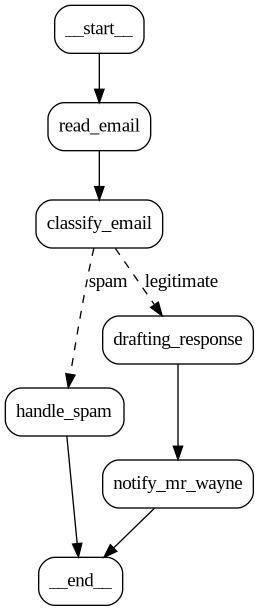

In [8]:
from IPython.display import Image, display

display_course_graph(compiled_graph.get_graph())

In [9]:
# Example emails for testing
legitimate_email = {
    "sender": "Joker",
    "subject": "Found you Batman ! ",
    "body": "Mr. Wayne,I found your secret identity ! I know you're batman ! Ther's no denying it, I have proof of that and I'm coming to find you soon. I'll get my revenge. JOKER"
}

spam_email = {
    "sender": "Crypto bro",
    "subject": "The best investment of 2025",
    "body": "Mr Wayne, I just launched an ALT coin and want you to buy some !"
}

In [10]:
class CourseMailTrace(BaseCallbackHandler):
    def __init__(self):
        self.nodes = []

    def on_chain_start(self, serialized, inputs, *, name=None, **kwargs):
        if name in {"read_email", "classify_email", "handle_spam", "drafting_response", "notify_mr_wayne"}:
            self.nodes.append(name)

def process_course_email(email, callbacks):
    return compiled_graph.invoke({"email": email, "messages": []},
                                 config={"callbacks": callbacks})

trace = CourseMailTrace()
legitimate_result = process_course_email(legitimate_email, [trace])
spam_result = process_course_email(spam_email, [trace])
assert legitimate_result["is_spam"] is False and legitimate_result["email_draft"]
assert spam_result["is_spam"] is True and not spam_result.get("email_draft")
print("Actual graph nodes:", trace.nodes)
assert "handle_spam" in trace.nodes and "notify_mr_wayne" in trace.nodes

Alfred is processing an email from Joker with subject: Found you Batman ! 
Groq text candidates, in order: qwen/qwen3.8-27b, openai/gpt-oss-20b, openai/gpt-oss-120b
Groq fallback model: openai/gpt-oss-20b
HAM

Sir, you've received an email from Joker.
Subject: Found you Batman ! 

I've prepared a draft response for your review:
--------------------------------------------------
Subject: Re: Found you Batman !

Dear Mr. Joker,

Thank you for reaching out. I appreciate your concern and the seriousness of your message. I would be grateful if you could provide the evidence you mentioned so that we can address this matter appropriately.

Please let me know a convenient time for a brief discussion. I am committed to resolving this situation in a constructive and professional manner.

Respectfully,

Bruce Wayne

Alfred is processing an email from Crypto bro with subject: The best investment of 2025
SPAM
Alfred has marked the email as spam.
Course simulation: the email would move to the spam f

langchain-openai injected a custom httpx transport to apply `http_socket_options`, which disables httpx's proxy auto-detection (system proxy configuration detected). Set `LANGCHAIN_OPENAI_TCP_KEEPALIVE=0` or pass `http_socket_options=()` to restore default proxy behavior, or supply `openai_proxy` / your own `http_client` / `http_async_client` to take full control.


## Step 5: Inspecting Our Mail Sorting Agent with Langfuse 📡

As Alfred fine-tunes the Main Sorting Agent, he's growing weary of debugging its runs. Agents, by nature, are unpredictable and difficult to inspect. But since he aims to build the ultimate Spam Detection Agent and deploy it in production, he needs robust traceability for future monitoring and analysis.

To do this, Alfred can use an observability tool such as [Langfuse](https://langfuse.com/) to trace and monitor the inner steps of the agent.

First, we need to install the necessary dependencies:

In [11]:
ENABLE_LANGFUSE = False  # Set True to export course example traces to your configured project.

Next, we set the Langfuse API keys and host address as environment variables. You can get your Langfuse credentials by signing up for [Langfuse Cloud](https://cloud.langfuse.com) or [self-hosting Langfuse](https://langfuse.com/self-hosting).

In [12]:
if ENABLE_LANGFUSE:
    for key_name in ("LANGFUSE_PUBLIC_KEY", "LANGFUSE_SECRET_KEY"):
        value = optional_secret(key_name)
        if not value:
            raise RuntimeError(f"Configure {key_name} for cloud tracing.")
        os.environ[key_name] = value
    os.environ["LANGFUSE_HOST"] = optional_secret("LANGFUSE_HOST") or "https://cloud.langfuse.com"
else:
    print("Langfuse Cloud is disabled. The previous cell records the actual local graph trace.")

Langfuse Cloud is disabled. The previous cell records the actual local graph trace.


Now, we configure the [Langfuse `callback_handler`](https://langfuse.com/docs/integrations/langchain/tracing#add-langfuse-to-your-langchain-application).

In [13]:
if ENABLE_LANGFUSE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "langfuse>=3,<4"], check=True, timeout=180)
    from langfuse.langchain import CallbackHandler
    langfuse_handler = CallbackHandler()

We then add `config={"callbacks": [langfuse_handler]}` to the invocation of the agents and run them again.

In [14]:
if ENABLE_LANGFUSE:
    process_course_email(legitimate_email, [langfuse_handler])
    process_course_email(spam_email, [langfuse_handler])
    from langfuse import get_client
    get_client().flush()

Alfred is now connected 🔌! The runs from LangGraph are being logged in Langfuse, giving him full visibility into the agent's behavior. With this setup, he's ready to revisit previous runs and refine his Mail Sorting Agent even further.

![Example trace in Langfuse](https://langfuse.com/images/cookbook/huggingface-agent-course/langgraph-trace-legit.png)

_[Public link to the trace with the legit email](https://cloud.langfuse.com/project/cloramnkj0002jz088vzn1ja4/traces/f5d6d72e-20af-4357-b232-af44c3728a7b?timestamp=2025-03-17T10%3A13%3A28.413Z&observation=6997ba69-043f-4f77-9445-700a033afba1)_

![Example trace in Langfuse](https://langfuse.com/images/cookbook/huggingface-agent-course/langgraph-trace-spam.png)

_[Public link to the trace with the spam email](https://langfuse.com/project/cloramnkj0002jz088vzn1ja4/traces/6e498053-fee4-41fd-b1ab-d534aca15f82?timestamp=2025-03-17T10%3A13%3A30.884Z&observation=84770fc8-4276-4720-914f-bf52738d44ba)_
